# Préparation du dataset WLASL100 final

Ce notebook documente la partie **Data** du projet de reconnaissance de langue des signes.

## Objectif

Construire un dataset propre, cohérent et directement exploitable par la partie modèle, sans fuite de signers entre `train`, `val` et `test`.

Pipeline :

`WLASL → disponibilité → nettoyage → qualité → sélection des classes → split signer-aware → MediaPipe → normalisation → séquences (60, 225)`

La partie **LSTM / entraînement / évaluation du modèle** n'est pas couverte ici.

## 1. Résultat final

- **100 classes**
- **1042 vidéos**
- **50 signers**
- **579 vidéos train**
- **295 vidéos validation**
- **168 vidéos test**
- **0 chevauchement de signers entre les splits**
- **1042/1042 extractions MediaPipe réussies**
- **shape finale de chaque séquence : `(60, 225)`**

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "asl"
FINAL_CSV = DATA_DIR / "final_wlasl100_split_v2.csv"
MANIFEST_CSV = DATA_DIR / "final_dataset_manifest.csv"
SUMMARY_CSV = DATA_DIR / "final_dataset_summary.csv"
CLASSES_JSON = DATA_DIR / "classes.json"
KEYPOINT_REPORT = DATA_DIR / "keypoints_extraction_report.csv"
print("Racine du projet :", ROOT)

Racine du projet : \\wsl.localhost\Ubuntu\home\kachair\moroccan-sign-language-ai


## 2. Charger le dataset final

In [2]:
df = pd.read_csv(FINAL_CSV)
print("Nombre de vidéos :", len(df))
print("Nombre de classes :", df["gloss"].nunique())
print("Nombre de signers :", df["signer_id"].nunique())
df.head()

Nombre de vidéos : 1042
Nombre de classes : 100
Nombre de signers : 50


,video,gloss,signer_id,source,original_split,frame_start,frame_end,metadata_fps,origin,split
0,69241.mp4,BOOK,118,aslbrick,train,1,-1,25,CURRENT,train
1,68011.mp4,BOOK,110,valencia-asl,train,1,-1,25,CURRENT,train
2,68012.mp4,BOOK,109,valencia-asl,train,1,-1,25,CURRENT,train
3,70212.mp4,BOOK,121,northtexas,val,2150,2249,25,CURRENT,train
4,70266.mp4,BOOK,121,northtexas,train,3732,3852,25,CURRENT,train


## 3. Répartition train / validation / test

Le split est fait **par signer** : un même signer ne doit jamais apparaître dans plusieurs splits.

In [3]:
split_counts = df["split"].value_counts()
split_percent = (df["split"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"videos": split_counts, "pourcentage": split_percent}))

,videos,pourcentage
split,,
train,579,55.57
val,295,28.31
test,168,16.12


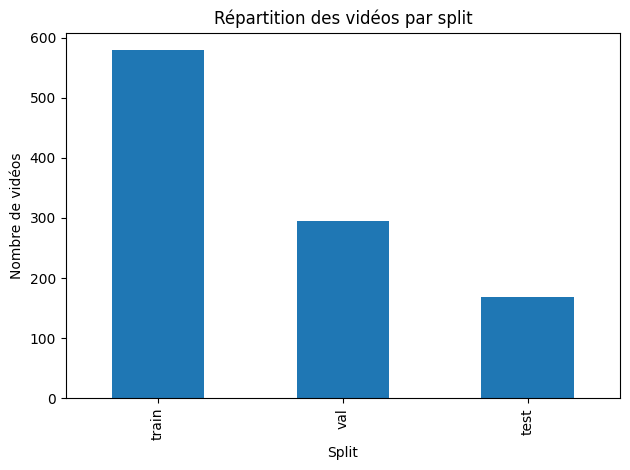

In [4]:
split_counts.plot(kind="bar")
plt.title("Répartition des vidéos par split")
plt.xlabel("Split")
plt.ylabel("Nombre de vidéos")
plt.tight_layout()
plt.show()

## 4. Vérification de l'absence de fuite de signers

In [5]:
train_signers = set(df.loc[df["split"] == "train", "signer_id"])
val_signers = set(df.loc[df["split"] == "val", "signer_id"])
test_signers = set(df.loc[df["split"] == "test", "signer_id"])
print("Train ∩ Val  :", len(train_signers & val_signers))
print("Train ∩ Test :", len(train_signers & test_signers))
print("Val ∩ Test   :", len(val_signers & test_signers))
assert len(train_signers & val_signers) == 0
assert len(train_signers & test_signers) == 0
assert len(val_signers & test_signers) == 0
print("✅ Aucun signer partagé entre les splits.")

Train ∩ Val  : 0
Train ∩ Test : 0
Val ∩ Test   : 0
✅ Aucun signer partagé entre les splits.


## 5. Répartition des vidéos par classe

count    100.000000
mean      10.420000
std        1.706671
min        8.000000
25%        9.000000
50%       10.000000
75%       11.000000
max       17.000000
dtype: float64

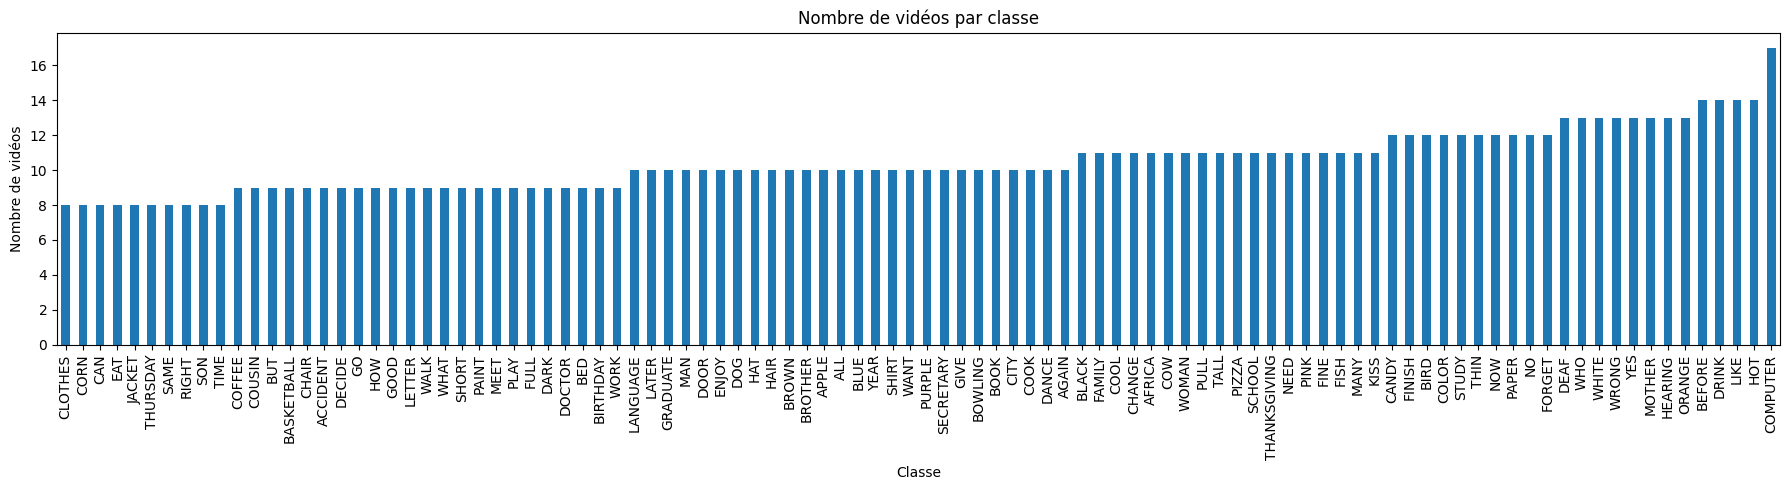

In [6]:
class_counts = df.groupby("gloss").size().sort_values()
display(class_counts.describe())
class_counts.plot(kind="bar", figsize=(18,5))
plt.title("Nombre de vidéos par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre de vidéos")
plt.tight_layout()
plt.show()

## 6. Vérifier que les 100 classes sont présentes dans chaque split

In [7]:
per_class_split = df.pivot_table(index="gloss", columns="split", values="video", aggfunc="count", fill_value=0)
for split in ["train","val","test"]:
    print(f"Classes absentes dans {split} :", int((per_class_split[split] == 0).sum()))
display(per_class_split.sort_values(["train","val","test"]).head(20))

Classes absentes dans train : 0
Classes absentes dans val : 0
Classes absentes dans test : 0


split,test,train,val
gloss,,,
CAN,2,3,3
SAME,2,3,3
BUT,2,3,4
BROTHER,5,4,1
RIGHT,2,4,2
SON,2,4,2
COUSIN,3,4,2
WALK,3,4,2
CLOTHES,1,4,3


## 7. Remplacement des classes faibles

Classes retirées : `TELL`, `LAST`, `HELP`, `CHEAT`, `MEDICINE`, `TABLE`.

Classes ajoutées : `AGAIN`, `BROTHER`, `COFFEE`, `DOOR`, `GOOD`, `HAIR`.

Le choix a été fait à partir des vidéos réellement disponibles et propres, de la diversité des signers et des sources.

## 8. Extraction MediaPipe

Chaque frame est transformée en **225 valeurs** :
- Pose : `33 × 3 = 99`
- Main gauche : `21 × 3 = 63`
- Main droite : `21 × 3 = 63`

Total : `225 features par frame`.

In [8]:
kp = pd.read_csv(KEYPOINT_REPORT)
print("Vidéos analysées :", len(kp))
print("Succès :", int(kp["success"].sum()))
print("Échecs :", int((~kp["success"]).sum()))
display(kp["frames"].describe())

Vidéos analysées : 1042
Succès : 1042
Échecs : 0


count    1042.000000
mean       74.343570
std        27.981313
min        19.000000
25%        56.000000
50%        73.500000
75%        90.000000
max       212.000000
Name: frames, dtype: float64

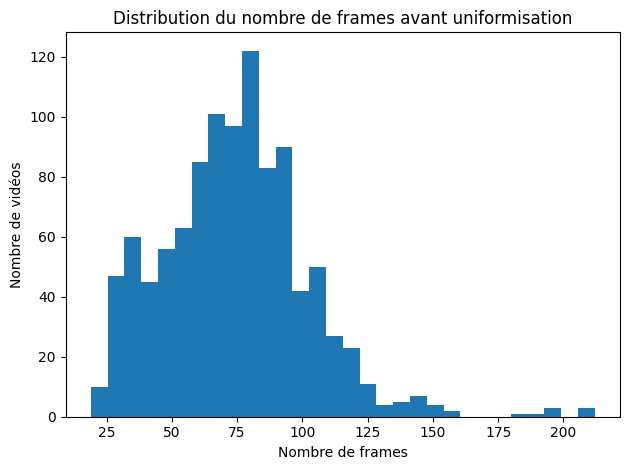

In [9]:
kp["frames"].plot(kind="hist", bins=30)
plt.title("Distribution du nombre de frames avant uniformisation")
plt.xlabel("Nombre de frames")
plt.ylabel("Nombre de vidéos")
plt.tight_layout()
plt.show()

## 9. Normalisation spatiale

Les coordonnées sont normalisées à partir des épaules : centre = milieu des épaules ; échelle = distance entre les épaules. Cela réduit l'influence de la position et de la distance à la caméra.

## 10. Uniformisation temporelle

Toutes les séquences sont rééchantillonnées à **60 frames**. La shape finale attendue est `(60, 225)`.

In [10]:
manifest = pd.read_csv(MANIFEST_CSV)
print("Séquences finales :", len(manifest))
print("Succès :", int(manifest["success"].sum()))
print("Échecs :", int((~manifest["success"]).sum()))
display(manifest["status"].value_counts())

Séquences finales : 1042
Succès : 1042
Échecs : 0


status
OK    1042
Name: count, dtype: int64

## 11. Vérifier quelques fichiers `.npy`

In [11]:
sample = manifest[manifest["success"]].head(10)
for _, row in sample.iterrows():
    path = ROOT / row["sequence_file"]
    arr = np.load(path)
    print(row["video"], row["gloss"], row["split"], arr.shape)
    assert arr.shape == (60,225)
    assert np.isfinite(arr).all()
print("✅ Les séquences testées sont valides.")

69241.mp4 BOOK train (60, 225)
68011.mp4 BOOK train (60, 225)
68012.mp4 BOOK train (60, 225)
70212.mp4 BOOK train (60, 225)
70266.mp4 BOOK train (60, 225)
07069.mp4 BOOK train (60, 225)
07068.mp4 BOOK train (60, 225)
07070.mp4 BOOK test (60, 225)
07075.mp4 BOOK val (60, 225)
07076.mp4 BOOK val (60, 225)
✅ Les séquences testées sont valides.


## 12. Vérification globale des séquences

In [12]:
errors = []
for _, row in manifest.iterrows():
    path = ROOT / row["sequence_file"]
    if not path.exists():
        errors.append((row["video"], "missing")); continue
    arr = np.load(path)
    if arr.shape != (60,225):
        errors.append((row["video"], f"shape={arr.shape}")); continue
    if not np.isfinite(arr).all():
        errors.append((row["video"], "NaN/Inf"))
print("Nombre d'erreurs :", len(errors))
if errors:
    display(pd.DataFrame(errors, columns=["video","error"]).head(20))
else:
    print("✅ Toutes les séquences sont prêtes pour la partie modèle.")

Nombre d'erreurs : 0
✅ Toutes les séquences sont prêtes pour la partie modèle.


## 13. Fichiers à fournir à la partie modèle

- `data/asl/sequences_60/` : entrées du modèle
- `data/asl/final_dataset_manifest.csv` : vidéo, classe, label, signer, split, chemin
- `data/asl/classes.json` : correspondance classe ↔ label_id
- `data/asl/final_dataset_summary.csv` : résumé par classe et split
- `data/asl/final_wlasl100_split_v2.csv` : métadonnées finales et split
- `data/asl/final_signer_split_v2.csv` : répartition des signers

## 14. Frontière entre Data et Modèle

### Partie Data — terminée
Récupération, validation, correction des découpages, qualité, sélection des classes, split signer-aware, MediaPipe, normalisation, séquences `(60,225)`.

### Partie Modèle — ensuite
Dataset/DataLoader, LSTM, augmentation train, entraînement, validation, test, matrice de confusion, sauvegarde, webcam.

## Conclusion

Dataset final prêt : **100 classes**, **1042 vidéos**, **579 train / 295 val / 168 test**, **aucune fuite de signer**, **1042 séquences valides**, shape **(60,225)**.